Universidad Torcuato Di Tella

Licenciatura en Tecnología Digital

**Métodos Computacionales — Reconstrucción y regularización en imágenes tomográficas**

# **Trabajo Práctico — Ejercicio N°9: Reconstrucción tomográfica con regularización cuadrática**

Resolvemos todas las importaciones necesarias para el correcto funcionamiento del código.

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

Además, corremos los bloques necesarios de ejercicios anteriores para poder realizar este ejercicio:

In [22]:
# Ejercicio 3

# Definimos `X_fantoma`
X_fantoma:np.ndarray = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

# Aplanamos la matriz `X_fantoma` para dar lugar a `x_fantoma`
x_fantoma = X_fantoma.reshape(-1)

In [23]:
# Ejercicio 3
def mascara_rayo(n:int, direccion:tuple[int,int], s:int):
    r'''
    Recibe:
    - `n` -> dimensión de la matriz (se asume cuadrada).
    - `direccion` -> dirección del rayo (fija una familia de rayos paralelos).
    - `s` -> distancia del rayo al origen (fija un rayo).

    Devuelve:
    - La matriz que representa la mascara del rayo sobre la imagen.
    '''
    res:np.ndarray = np.zeros(shape=(n,n), dtype=np.int8)
    for i in range(0,len(res)):
        for j in range(0,len(res)):
            if (direccion[0] * i) + (direccion[1] * j) == s:
                res[i][j] = 1
    return res

In [24]:
# Ejercicio 3
def matriz_proyeccion(n:int, direcciones:list[tuple[int, int]]):
    r'''
    
    Recibe:
    - `n` -> dimensión de la matriz (se asume cuadrada).
    - `direcciones` -> vector de direcciones a utilizar.

    Devuelve:
    - La matriz compuesta por las máscaras de todos los rayos correspondientes.
    - La lista de todos los rayos generados, con el ángulo y el s correspondiente.
    '''
    A:list[list[int]] = list()
    res:list[tuple[tuple[int,int], int]] = list()
    for dir in direcciones:
        rayos:set[int] = set()
        for i in range(n):
            for j in range(n):
                s = dir[0] * i + dir[1] * j
                rayos.add(s)
        rayos_lista:list[int] = list(rayos)
        rayos_lista.sort()
        rayos_array:np.ndarray = np.array(rayos_lista)

        for rayo in rayos_array:
            fila_A = mascara_rayo(n, dir, rayo)
            fila_A = fila_A.reshape(-1)
            A.append(fila_A) # type: ignore
            res.append((dir, rayo))

    return A, res

In [25]:
# Ejercicio 4

# Para definir dimensiones de la matriz (nxn)
n = 8

D2 = [(1,0),(0,1)]
D4 = [(1,0),(0,1),(1,1),(1,-1)]
D7 = [(1,0),(0,1),(1,1),(1,-1),(2,1),(1,2),(3,1)]

# Construímos A2, A4, A7
A2 = matriz_proyeccion(n, D2)[0]
A4 = matriz_proyeccion(n, D4)[0]
A7 = np.array(matriz_proyeccion(n, D7)[0])

In [26]:
# Ejercicio 5

# Generemos las mediciones
b2 = A2 @ x_fantoma
b4 = A4 @ x_fantoma
b7 = A7 @ x_fantoma

In [27]:
# Ejercicio 6

# Determinamos una semilla aleatoria para garantizar reproducibilidad
SEED = 73
np.random.seed(SEED)

# Creamos el vector z del mismo tamaño que b7, es decir, 119
z = np.random.normal(loc=0.0, scale=1.0, size=119)

# Creamos la lista de desvios (sigma's)
desvios = [0, 0.01, 0.03, 0.06, 0.1]

# Calculamos escala
escala = np.sqrt(np.mean(b7**2))

# Creamos la lista de ruidos (eta's) donde habrá una por cada desvio
ruidos = list()

for ds in desvios:
    ruido = ds * escala * z
    ruidos.append(ruido)

1. Implementar `matriz_diferencias(n)` siguiendo la construcción anterior. Verificar que cada fila contiene exactamente un $−1$ y un $1$, y comprobar que para $n = 8$ se obtiene $D \in \mathbb{R}^{112 \times 64}$.

In [ ]:
def matriz_diferencias(n:int):
    '''
    Requiere: un entero n que representa la dimensión de la matriz sobre la cual se aplicará la matriz resultante.\n
    Devuelve: una matriz de diferencias D de tamaño 2n(n-1) x n².
    '''

    # Primero construimos el bloque Dh
    D = list()

    for i in range(n):
        for j in range(n-1):
            nueva_fila = np.zeros((n**2))
            nueva_fila[i*n + j] = -1
            nueva_fila[i*n + j+1] = 1
            D.append(nueva_fila)

    # Luego construimos el bloque Dv
    for j in range(n):
        for i in range(n-1):
            nueva_fila = np.zeros((n**2))
            nueva_fila[i*n + j] = -1
            nueva_fila[(i+1)*n + j] = 1
            D.append(nueva_fila)

    return np.array(D)

# Función para chequear que la suma de elementos da 0 para cada fila
def verificar_D(D:np.ndarray) -> bool:
    '''
    Requiere: una matriz D. \n
    Devuelve: `True` si hay exactamente un 1 y un -1 en cada fila. En caso contrario, devuelve `False`.
    '''

    for fila in D:
        if sum(fila) != 0: return False

    return True

Dimensión de D para n=8: (112, 64)
Es matriz de diferencias? -> True


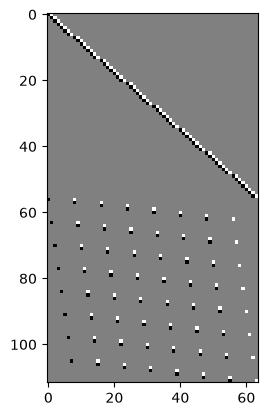

In [29]:
D8 = matriz_diferencias(n)
print("Dimensión de D para n=8:", np.shape(D8))
print("Es matriz de diferencias? ->", verificar_D(D8))

# Visualizamos la matriz D
plt.imshow(D8, cmap='gray')

Por lo tanto, verificamos que cada fila contiene exactamente un $-1$ y un $1$, y comprobamos que para $n=8$ se obtiene $D\in\mathbb{R}^{112\times 64}$.

2. Crear en Python el vector `x_constante = np.ones(n**2)`, que representa una imagen en la que todos los píxeles tienen valor $1$. Verificar que $Dx_{constante} = 0$ y explicar por qué todas las diferencias resultan nulas. Comparar este resultado con $∥Dx_{fantoma}∥$.

In [30]:
x_constante = np.ones(n**2)
Dx_constante = D8 @ x_constante
print("Dx_constante tiene dimensión", np.shape(Dx_constante))

print("Es Dx_constante nulo? ->", np.array_equal(Dx_constante, np.zeros((112))))
print("||Dx_constante|| =", np.linalg.norm(Dx_constante))

Dx_constante tiene dimensión (112,)
Es Dx_constante nulo? -> True
||Dx_constante|| = 0.0


En la imagen $x_{constante}$, todos los píxeles tienen el mismo valor de atenuación. Esto implica que, para cualquier par de píxeles, no hay ninguna diferencia entre ellos. Particularmente, para nuestro caso nos interesa saber que $x_{i,j} = x_{i,j+1}$ y $x_{i,j} = x_{i+1,j}$. De esta manera, naturalmente, todas las diferencias computadas mediante el producto $Dx_{constante}$ dan $0$.

Contrastando con $Dx_{fantoma}$:

In [31]:
Dx_fantoma = D8 @ x_fantoma

print("Dx_fantoma tiene dimensión", np.shape(Dx_fantoma))
print("Es Dx_fantoma nulo? ->", np.array_equal(Dx_fantoma, np.zeros((112))))
print("||Dx_fantoma|| =", np.linalg.norm(Dx_fantoma))

Dx_fantoma tiene dimensión (112,)
Es Dx_fantoma nulo? -> False
||Dx_fantoma|| = 2.7055498516937364


Analicemos las diferencias entre pares de forma más visual.

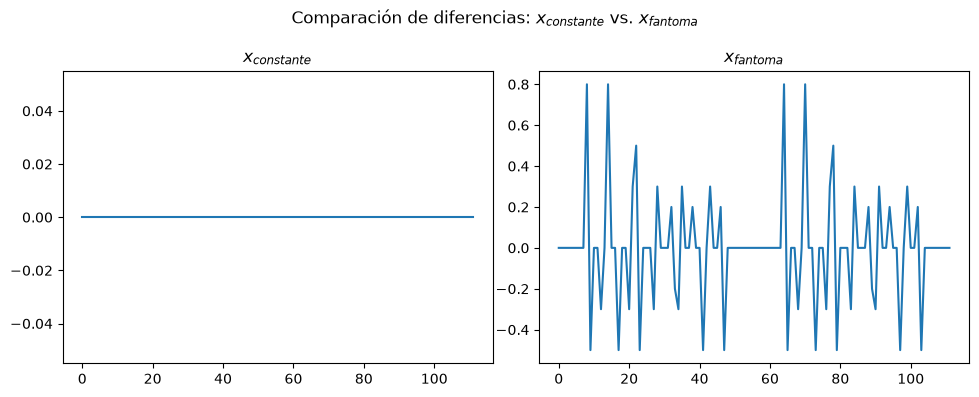

In [32]:
# Generamos una figura grande para graficar los subplots
plt.figure(figsize=(10, 4))

# Delimitamos un título general del plot
plt.suptitle("Comparación de diferencias: $x_{constante}$ vs. $x_{fantoma}$")

# Generamos los subplots
plt.subplot(1,2,1)
plt.title("$x_{constante}$")
plt.plot(Dx_constante)

plt.subplot(1,2,2)
plt.title("$x_{fantoma}$")

plt.tight_layout()
plt.plot(Dx_fantoma)

En el caso de la tomografía simulada, no todos los pares de píxeles horizontales y verticales tienen la misma atenuación. Entonces, resulta natural que no todas las diferencias devuelvan $0$.

3. Interpretar las expresiones provistas. Explicar qué mide cada término de $J_{\sigma,\lambda}$, qué representa $∥D_x∥$ y cuál es el papel de $\lambda$.

Primero que nada, recordemos la definición provista en la consigna:

$$J_{\sigma,\lambda}(x)=\frac{1}{2}(||A_7x-b_\sigma||^2 + \lambda||Dx||^2)$$

$J_{\sigma,\lambda}(x)$ es una función objetivo a minimizar a través de métodos iterativos (tales como el método del gradiente y el método de Newton) para obtener una reconstrucción $\hat{x}_\sigma$ lo más fiable posible. El primer término $||A_7x-b_\sigma||$ mide la distancia entre la mejor solución hallada hasta el momento y las mediciones, tal como se hacía en el ejercicio anterior. El segundo término, además, penaliza de acuerdo a la norma del vector de diferencias $||Dx||$. Esto implica que, en los términos de esta nueva función, cuanto más pronunciadas sean las diferencias entre los diferentes pares horizontales y verticales de píxeles, peor será la solución hallada. El coeficiente $\lambda$ se encarga de regular la intensidad de la penalización: a mayor $\lambda$, mayor es el costo numérico de las diferencias.

4. Reutilizar las mediciones limpias $b_7 = A_7 x_{fantoma}$ y el vector aleatorio $z$ del ejercicio sobre ruido.
Generar mediciones para $\sigma \in \{0, 0.10, 0.20\}$ mediante:

`escala = np.sqrt(np.mean(b7**2))`

`b_sigma = b7 + sigma * escala * z`

Utilizar el mismo vector $z$ en los tres casos, de modo que sólo cambie la intensidad del ruido.

In [33]:
# escala y z ya fueron importados de forma preliminar más arriba en el notebook

b_sigma_00 = b7   # (0 * escala * z) =  vector 0
b_sigma_01 = b7 + (0.1 * escala * z)
b_sigma_02 = b7 + (0.2 * escala * z)

5. Adaptar gradiente descendiente para minimizar $J_{\sigma,\lambda}$ para cada combinación de $\sigma \in \{0, 0.10, 0.20\}$ y $\lambda \in \{0, 0.1, 0.3, 1\}$. Comenzar siempre con $x_0 = \bar{0}$.

In [34]:
# Definimos la función objetivo
def J(x:np.array, b:np.array, D:np.ndarray, lmbd:float):
    '''
    Requiere:

    - Un vector de solución parcial `x`.
    - Un vector de mediciones `b` sobre el cual comparar.
    - Una matriz `D` de diferencias.
    - Un float `lmbd` para regular la penalización por diferencias.

    Devuelve: un número flotante que resulta de evaluar la función objetivo con los parámetros dados.
    '''
    t1 = np.linalg.norm( (A7 @ x) - b )
    t2 = np.linalg.norm( D @ x )
    return 0.5 * (t1**2 + lmbd * (t2**2))

# Definimos el gradiente de la función objetivo
def grad_J(x:np.array, b:np.array, D:np.ndarray, lmbd:float):
    '''
    Requiere:

    - Un vector de solución parcial `x`.
    - Un vector de mediciones `b` sobre el cual comparar.
    - Una matriz `D` de diferencias.
    - Un float `lmbd` para regular la penalización por diferencias.

    Devuelve: un número flotante que resulta de evaluar el gradiente de la función objetivo.
    '''
    t1 = A7.transpose() @ (A7@x -b)
    t2 = lmbd * (D.transpose() @ D @ x)
    return t1 + t2

In [35]:
# Adaptación del método del gradiente
def gradiente_descendente_v2(x_0, bs, D, lmbd, alpha = 0.01, tolerancia = 0.0001, max_iter = 1000, verbose=False):
    '''
    Requiere:

    - Un vector de solución parcial `x`.
    - Un vector de mediciones `b` sobre el cual comparar.
    - Una matriz `D` de diferencias.
    - Un float `lmbd` para regular la penalización por diferencias.
    - (Opcional) Un float `alpha` que representa la tasa de aprendizaje (0.01 por defecto).
    - (Opcional) Un float `tolerancia` que funciona como criterio para seguir iterando (0.01 por defecto).
    - (Opcional) Un entero `max_iter` como cota superior de las iteraciones del método (1000 por defecto).
    - (Opcional) Un bool `verbose` para imprimir los resultados de las iteraciones (0.01 por defecto).

    Devuelve: un objeto `tuple` con un vector de la mejor solución hallada, un vector de costos y un vector con las normas del gradiente.
    '''

    x_t   = x_0

    cost_log = list()
    grad_norm_log = list()

    iter  = 0

    while iter <= max_iter:
        
        x_tsig = x_t - alpha * grad_J(x=x_t, b=bs, D=D, lmbd=lmbd)

        cost_log.append( J(x=x_t, b=bs, D=D, lmbd=lmbd) )
        grad_norm_log.append(np.linalg.norm(grad_J(x=x_t, b=bs, D=D, lmbd=lmbd)))
        if verbose: print("Iteración", iter, "-> Mínimo hallado hasta ahora: ", J(x=x_t, b=bs, D=D, lmbd=lmbd), "-- Norma del gradiente: ", np.linalg.norm(grad_J(x=x_t, b=bs, D=D, lmbd=lmbd)))

        if abs( J(x=x_tsig, b=bs, D=D, lmbd=lmbd) - J(x=x_t, b=bs, D=D, lmbd=lmbd)) < tolerancia:
          break

        x_t = x_tsig
        iter = iter + 1

    return np.array(x_tsig), cost_log, grad_norm_log

6. Evaluar distintas tasas de aprendizaje y seleccionar una que produzca un descenso estable del
costo. Implementar un criterio de parada basado en la norma del gradiente o en la variación del
costo, junto con una cantidad máxima de iteraciones. El criterio de parada no debe utilizar el error
respecto del fantoma.

El algoritmo de descenso del gradiente implementado ya verifica las propiedades solicitadas respecto al criterio de parada. En particular, podemos decir que contamos con un ciclo finito de iteraciones limitado por el parámetro `max_iter` que a su vez esta sujeto a otra restricción que posibilita parar el ciclo si el valor absoluto de la diferencia entre las evaluaciones un *step* y el siguiente es menor al valor del parámetro `tolerancia` que funge de umbral.

A continuación, evalúamos distintos *learning rates* y seleccionamos aquel $\alpha$ que produzca un descenso estable del costo.

In [36]:
registro_x_rec = list()
registro_costo = list()
registro_grad = list()

alphas = [0.01, 0.02, 0.03, 0.04, 0.05, 0.054]

for a in alphas:
    x_rec, costo_log, grad_log = gradiente_descendente_v2(x_0 = np.zeros((64)), bs=b_sigma_02, D=D8, lmbd=1, alpha = a) # Partimos de la variante de medición más ruidosa -> sigma = 0,2
    registro_x_rec.append(x_rec)
    registro_costo.append(costo_log)
    registro_grad.append(grad_log)

Luego, tras obtener los resultados creamos una visualización del costo a lo largo de las iteraciones para cada caso.

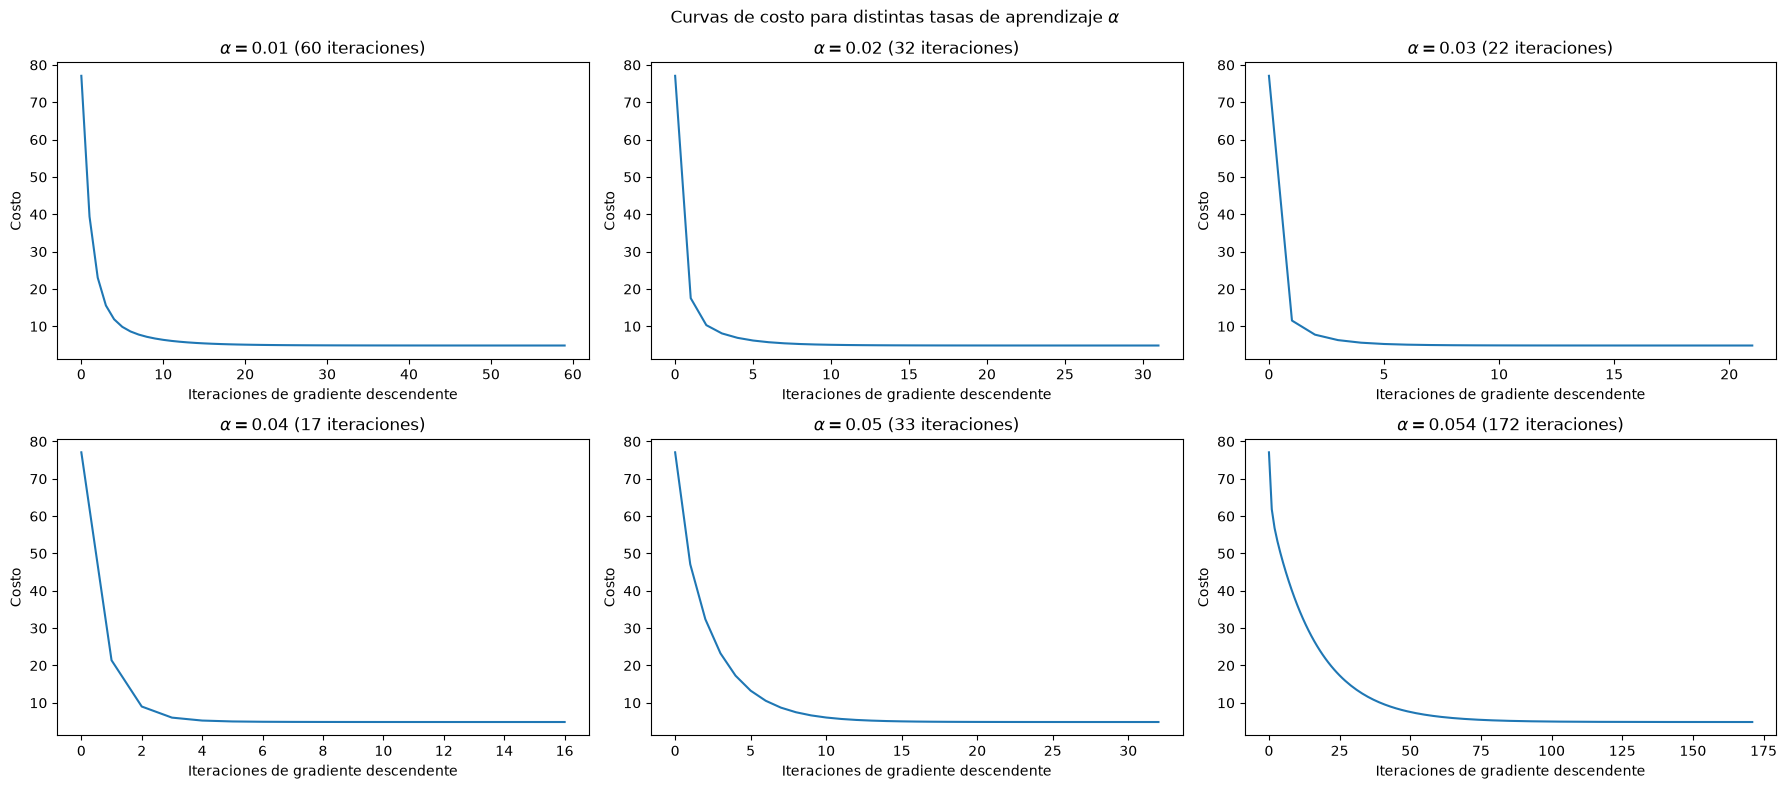

In [37]:
# Generamos una figura grande para graficar los subplots
plt.figure(figsize=(18, 8))

# Delimitamos un título general del plot
plt.suptitle(r"Curvas de costo para distintas tasas de aprendizaje $\alpha$")

# Generamos un gráfico para cada curva de costo
# En particular, una por cada valor de alpha
for i in range(len(registro_costo)):
    plt.subplot(2, 3, i+1)
    plt.plot(registro_costo[i])
    plt.title(rf'$\alpha = {alphas[i]}$ ({len(registro_costo[i])} iteraciones)')
    plt.ylabel('Costo')
    plt.xlabel('Iteraciones de gradiente descendente')

plt.tight_layout()
plt.show()

Como se puede observar, para todos los $\alpha$ propuestos se aprecia un descenso estable del costo (tampoco hubo ninguna divergencia). Para hilar fino y quedarnos con un único $\alpha$ planteamos la siguiente tabla comparativa:

In [38]:
df_alphas = pd.DataFrame({
    "alpha": alphas,
    "iteraciones": [len(registro_costo[0]), len(registro_costo[1]), len(registro_costo[2]), len(registro_costo[3]), len(registro_costo[4]), len(registro_costo[5])],
    "costo_final": [registro_costo[0][-1], registro_costo[1][-1], registro_costo[2][-1], registro_costo[3][-1], registro_costo[4][-1], registro_costo[5][-1]],
    "norma_grad_final": [registro_grad[0][-1], registro_grad[1][-1], registro_grad[2][-1], registro_grad[3][-1], registro_grad[4][-1], registro_grad[5][-1]],
})

df_alphas

,alpha,iteraciones,costo_final,norma_grad_final
0,0.010,60,4.855317,0.098994
1,0.020,32,4.854942,0.072156
2,0.030,22,4.854802,0.059552
3,0.040,17,4.854702,0.049205
4,0.050,33,4.854682,0.131863
5,0.054,172,4.856028,0.340030


En conclusión, determinamos como elección al $\alpha = 0,04$ pues fue el que menor cantidad de iteraciones (17) requirió para llegar a un costo óptimo semejante al de las demás alternativas, lo cual indica una convergencia más rápida. Además, la norma del gradiente tras la última iteración fue la menor por lo que hacia el final no debió desplazarse mucho para llegar al óptimo alcanzado (aquel que cumplió con el umbral de tolerancia delimitado). Por otro lado, reconocemos que ninguna de las alternativas divirgió.

7. Registrar durante las iteraciones el error relativo $e_t = \frac{||x_t −x_{\text{fantoma}}||}{||x_\text{fantoma}||}$. Para cada nivel
de ruido, graficar $e_t$ en función de las iteraciones para los distintos valores de $\lambda$.

In [39]:
# Adaptación del método del gradiente (incluyendo un log del error relativo)
def gradiente_descendente_v3(x_0, bs, D, lmbd, alpha = 0.01, tolerancia = 0.0001, max_iter = 1000, verbose=False):
    '''
    Requiere:

    - Un vector de solución parcial `x`.
    - Un vector de mediciones `b` sobre el cual comparar.
    - Una matriz `D` de diferencias.
    - Un float `lmbd` para regular la penalización por diferencias.
    - (Opcional) Un float `alpha` que representa la tasa de aprendizaje (0.01 por defecto).
    - (Opcional) Un float `tolerancia` que funciona como criterio para seguir iterando (0.01 por defecto).
    - (Opcional) Un entero `max_iter` como cota superior de las iteraciones del método (1000 por defecto).
    - (Opcional) Un bool `verbose` para imprimir los resultados de las iteraciones (0.01 por defecto).

    Devuelve: un objeto `tuple` con un vector de la mejor solución hallada, un vector de costos, un vector con las normas del gradiente y un vector de error relativo.
    '''

    x_t   = x_0

    cost_log = list()
    grad_norm_log = list()
    err_rel_log = list()

    iter  = 0

    while iter <= max_iter:
        
        x_tsig = x_t - alpha * grad_J(x=x_t, b=bs, D=D, lmbd=lmbd)

        cost_log.append( J(x=x_t, b=bs, D=D, lmbd=lmbd) )
        grad_norm_log.append(np.linalg.norm(grad_J(x=x_t, b=bs, D=D, lmbd=lmbd)))
        err_rel_log.append(np.linalg.norm(x_t - x_fantoma)/np.linalg.norm(x_fantoma))
        if verbose: print("Iteración", iter, "-> Mínimo hallado hasta ahora: ", J(x=x_t, b=bs, D=D, lmbd=lmbd), "-- Norma del gradiente: ", np.linalg.norm(grad_J(x=x_t, b=bs, D=D, lmbd=lmbd)))

        if abs( J(x=x_tsig, b=bs, D=D, lmbd=lmbd) - J(x=x_t, b=bs, D=D, lmbd=lmbd)) < tolerancia:
          break

        x_t = x_tsig
        iter = iter + 1

    return np.array(x_tsig), cost_log, grad_norm_log, err_rel_log

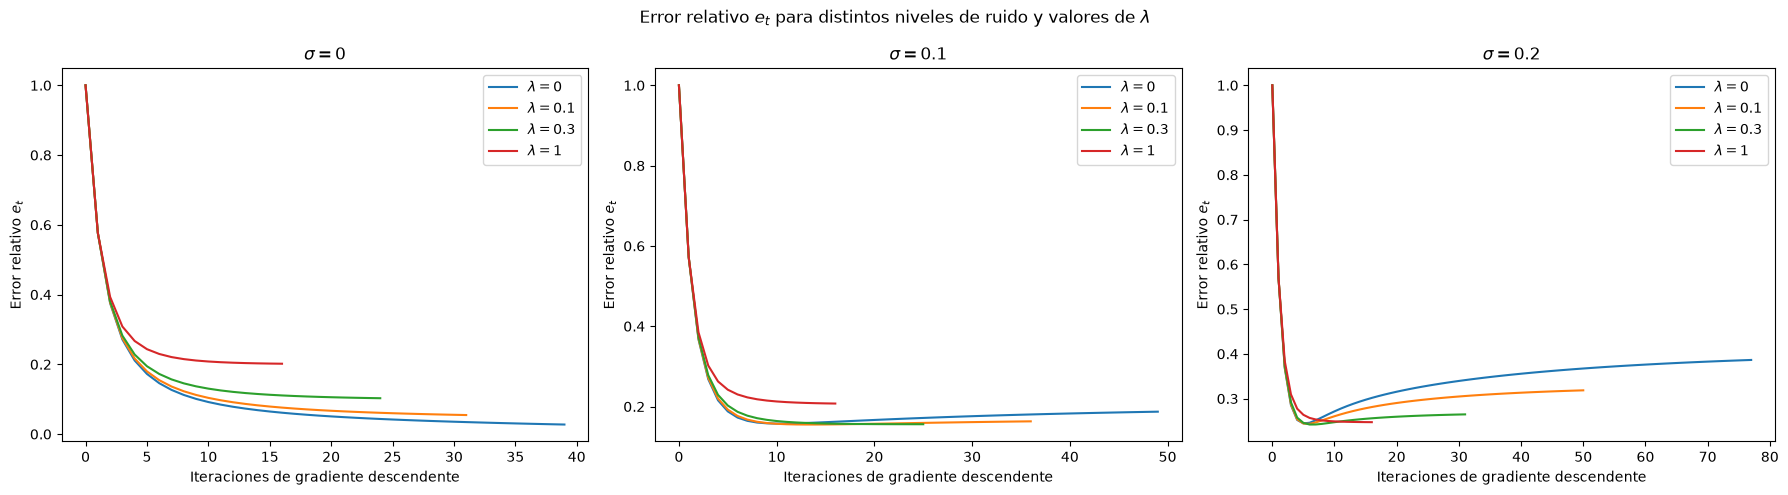

In [40]:
bs_por_sigma = {
    0: b_sigma_00, 
    0.1: b_sigma_01,
    0.2: b_sigma_02
}

lambdas = [0, 0.1, 0.3, 1]
ALPHA = 0.04  # el α elegido en el inciso anterior

# Generamos una figura para graficar los subplots
plt.figure(figsize=(18, 5))

# Delimitamos un título general del plot
plt.suptitle(r"Error relativo $e_t$ para distintos niveles de ruido y valores de $\lambda$")

# Generamos un gráfico por cada nivel de ruido
# En cada uno, una curva por cada valor de lambda
for i, (sigma, b) in enumerate(bs_por_sigma.items()):
    plt.subplot(1, 3, i+1)

    for lmbd in lambdas:
        _, _, _, err_rel_log = gradiente_descendente_v3(x_0=np.zeros(64), bs=b, D=D8, lmbd=lmbd, alpha=ALPHA)
        plt.plot(err_rel_log, label=rf'$\lambda = {lmbd}$') # Label luego enlazado con la leyenda

    plt.title(rf'$\sigma = {sigma}$')
    plt.ylabel(r'Error relativo $e_t$')
    plt.xlabel('Iteraciones de gradiente descendente')
    plt.legend()

plt.tight_layout()
plt.show()

8. Organizar las reconstrucciones finales en una grilla: cada fila debe corresponder a un valor de $\sigma$ y
cada columna, a un valor de $\lambda$. Utilizar la misma escala de color en todas las imágenes, sin ajustar
automáticamente los límites de cada panel, e indicar el error relativo sobre cada reconstrucción.

<>:3: SyntaxWarning: invalid escape sequence '\s'
<>:3: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_15763/4063227899.py:3: SyntaxWarning: invalid escape sequence '\s'
  plt.suptitle("Variantes de las imágenes bajo diferentes $\sigma$ y $\lambda$")


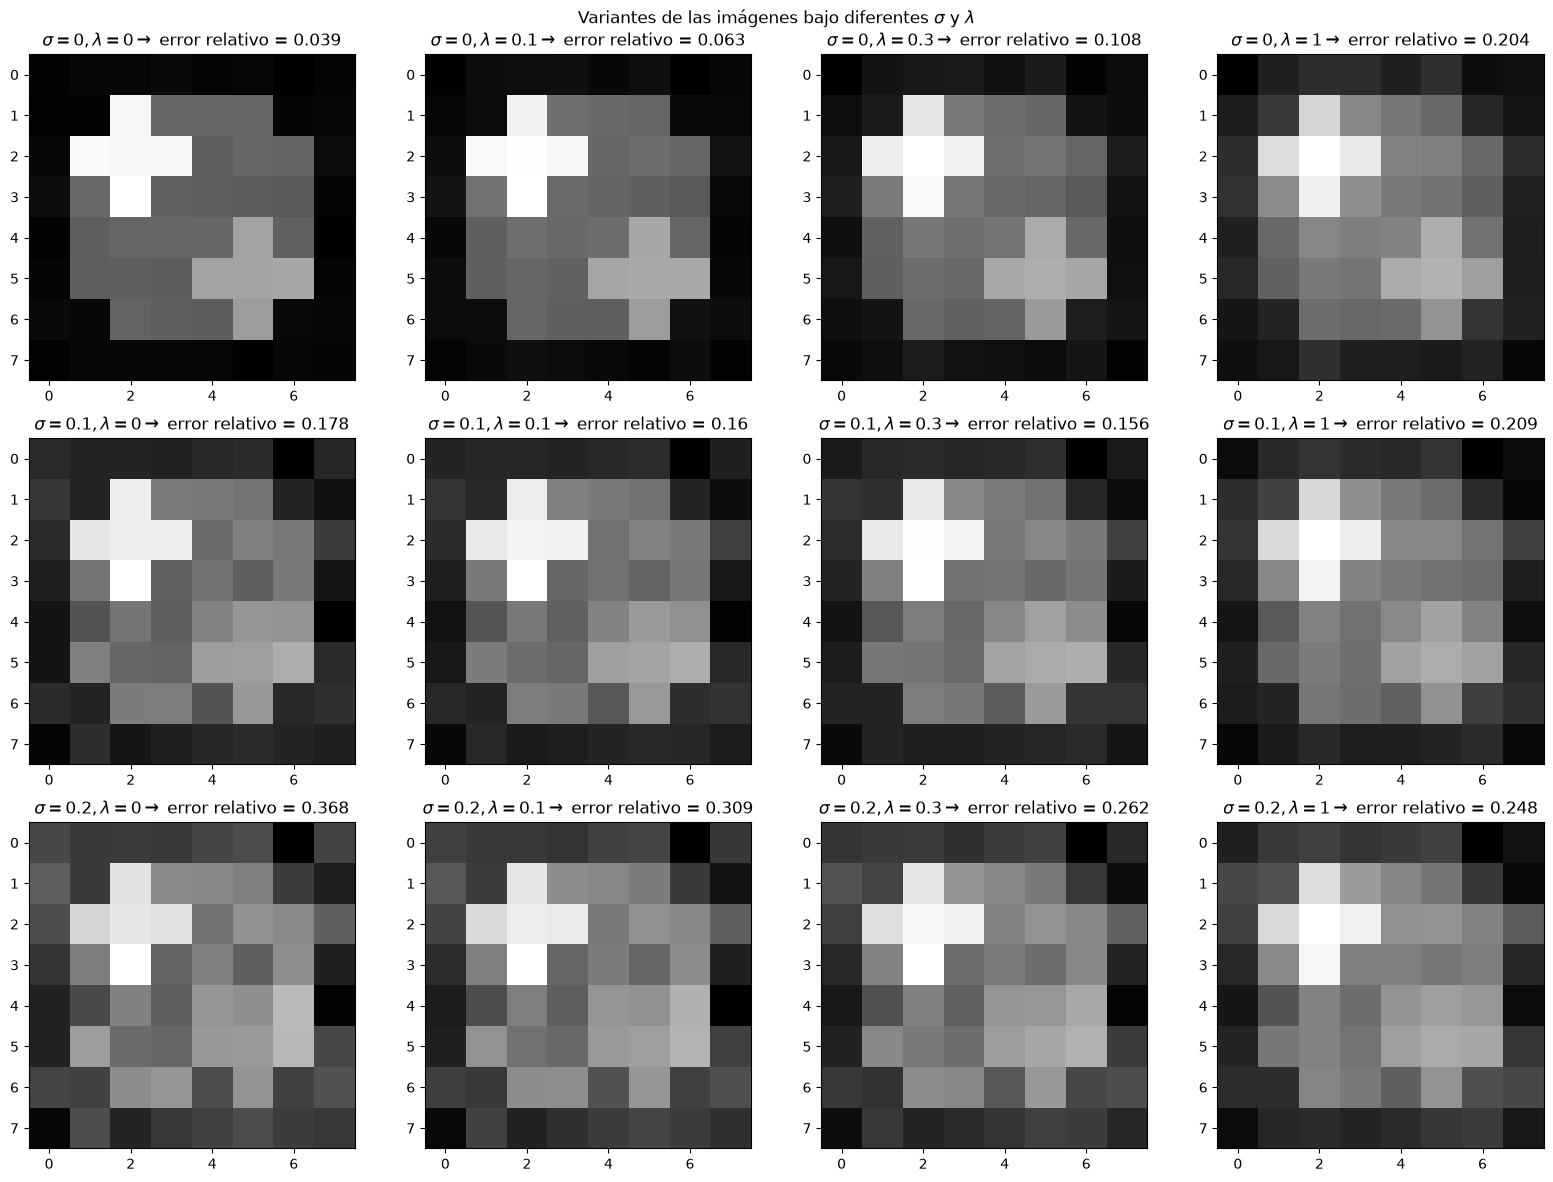

In [44]:
# Generamos la figura para graficar los subplots
plt.figure(figsize=(16, 12))
plt.suptitle("Variantes de las imágenes bajo diferentes $\sigma$ y $\lambda$")

matrix_err_rel = list([list(), list(), list()])

# Para cada sigma y cada lambda, reconstruímos y graficamos
for i, (sigma, b) in enumerate(bs_por_sigma.items()):
    for j, lmbd in enumerate(lambdas):
        x_rec, _, _, _ = gradiente_descendente_v3(np.zeros(64), bs=b, D=D8, lmbd=lmbd)
        
        # Calculamos el error relativo
        err_rel = np.linalg.norm(x_rec - x_fantoma) / np.linalg.norm(x_fantoma)
        matrix_err_rel[i].append(err_rel)

        plt.subplot(len(bs_por_sigma), len(lambdas), i*len(lambdas) + j + 1)

        # Redondeamos el error relativo a tres decimales para mejor legibilidad
        plt.title(rf"$\sigma = {sigma}, \lambda = {lmbd} \rightarrow$ error relativo = {round(err_rel, 3)}")
        plt.imshow(x_rec.reshape(8, 8), cmap='gray')

plt.tight_layout()
plt.show()

9. Resumir los errores relativos y las normas de los residuos en una tabla o mapa de calor cuyos ejes
sean $\sigma$ y $\lambda$. Para cada nivel de ruido, identificar qué valor de $\lambda$ produjo el menor error.

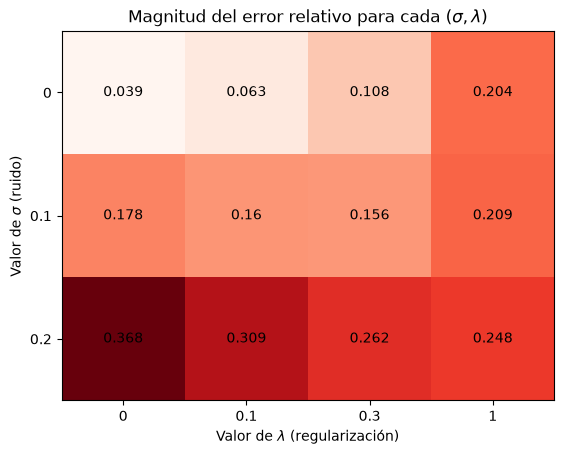

In [58]:
sigmas = [0, 0.1, 0.2]

fig, ax = plt.subplots()

ax.set_xticks(range(len(lambdas)), labels=lambdas)
ax.set_yticks(range(len(sigmas)), labels=sigmas)

for i in range(len(sigmas)):
    for j in range(len(lambdas)):
        text = ax.text(j, i, round(number=matrix_err_rel[i][j], ndigits=3),
                       ha="center", va="center")

plt.xlabel(r"Valor de $\lambda$ (regularización)")
plt.ylabel(r"Valor de $\sigma$ (ruido)")

plt.title(r"Magnitud del error relativo para cada ($\sigma, \lambda$)")

im = ax.imshow(matrix_err_rel, cmap='Reds')

- Para $\sigma = 0$, $\lambda = 0$ produjo el mejor resultado ($\epsilon = 0.039$).
- Para $\sigma = 0.1$, $\lambda = 0.1$ produjo el mejor resultado ($\epsilon = 0.16$).
- Para $\sigma = 0.2$, $\lambda = 1$ produjo el mejor resultado ($\epsilon = 0.248$).

10. Analizar los resultados. ¿En qué casos la regularización mejoró la reconstrucción obtenida con $\lambda = 0$? ¿Cómo cambió el valor más conveniente de $\lambda$ al aumentar el ruido? ¿Qué efecto produjo una regularización excesiva?

Tras los análisis realizados, se puede observar que, para valores bajos de $\sigma$, la regularización obtuvo los mejores resultados con $\lambda = 0$ (la regularización empeoró los resultados obtenidos) . Por otro lado, a medida que el ruido aumentaba $\sigma\uparrow$, la reconstrucción mejoraba con valores más altos de $\lambda$. 

A efectos prácticos, se puede ver que la regularización excesiva deriva en una reconstrucción con bajo contraste (más difusa a simple vista) ya que justamente penaliza la presencia de pixeles contiguos de alto contraste. Sin embargo, esta técnica es "ciega" a la naturaleza del contraste que observa, por lo que no es capaz de distinguir entre las disparidades introducidas por el ruido y los contrastes propios de la imagen original. Es por esto que, si bien la regularización puede mitigar el efecto del ruido, cuando este es bajo, es muy propensa a suavizar el contraste de la reconstrucción incluso si no hacerlo produjera una solución más cercana a la tomografía real.

